In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")

Libraries imported successfully!


In [18]:
df = pd.read_csv("../data/raw/ted_talks_en.csv")

print("Dataset loaded successfully!")
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

Dataset loaded successfully!
Number of rows: 4005
Number of columns: 19


In [3]:
print("Column names:")
print(df.columns.tolist())

print("\nData types of each column:")
print(df.dtypes)

Column names:
['talk_id', 'title', 'speaker_1', 'all_speakers', 'occupations', 'about_speakers', 'views', 'recorded_date', 'published_date', 'event', 'native_lang', 'available_lang', 'comments', 'duration', 'topics', 'related_talks', 'url', 'description', 'transcript']

Data types of each column:
talk_id             int64
title                 str
speaker_1             str
all_speakers          str
occupations           str
about_speakers        str
views               int64
recorded_date         str
published_date        str
event                 str
native_lang           str
available_lang        str
comments          float64
duration            int64
topics                str
related_talks         str
url                   str
description           str
transcript            str
dtype: object


In [4]:
print("Descriptive Statistics:")
display(df.describe())

print("\nMedian values:")
display(df.median(numeric_only=True))

Descriptive Statistics:


,talk_id,views,comments,duration
count,4005.000000,4.005000e+03,3350.000000,4005.000000
mean,12432.538327,2.148006e+06,161.997015,724.011236
std,17447.576262,3.451226e+06,268.838922,361.775462
min,1.000000,0.000000e+00,0.000000,60.000000
25%,1252.000000,8.820690e+05,38.000000,393.000000
50%,2333.000000,1.375508e+06,89.000000,738.000000
75%,23777.000000,2.133110e+06,188.000000,974.000000
max,62794.000000,6.505195e+07,6449.000000,3922.000000



Median values:


talk_id        2333.0
views       1375508.0
comments         89.0
duration        738.0
dtype: float64

In [5]:
missing_report = pd.DataFrame({
    "Missing Count": df.isnull().sum(),
    "Missing Percentage": (df.isnull().sum() / len(df) * 100).round(2)
})

display(missing_report)

,Missing Count,Missing Percentage
talk_id,0,0.00
title,0,0.00
speaker_1,0,0.00
all_speakers,4,0.10
occupations,522,13.03
about_speakers,503,12.56
views,0,0.00
recorded_date,1,0.02
published_date,0,0.00
event,0,0.00


In [6]:
print("Duplicate rows:", df.duplicated().sum())

print("Repeated talk IDs:", df["talk_id"].duplicated().sum())

print("Unique talk IDs:", df["talk_id"].nunique())

Duplicate rows: 0
Repeated talk IDs: 0
Unique talk IDs: 4005


In [7]:
important_columns = [
    "title", "description", "tags", "topics",
    "transcript", "url"
]

for col in important_columns:
    if col in df.columns:
        missing = df[col].isnull().sum()
        empty = (
            df[col].astype("string").str.strip().eq("").fillna(False).sum()
        )

        print(f"\nColumn: {col}")
        print("Missing values:", missing)
        print("Empty values:", empty)
    else:
        print(f"\nColumn '{col}' is not available in the dataset.")


Column: title
Missing values: 0
Empty values: 0

Column: description
Missing values: 0
Empty values: 0

Column 'tags' is not available in the dataset.

Column: topics
Missing values: 0
Empty values: 0

Column: transcript
Missing values: 0
Empty values: 0

Column: url
Missing values: 0
Empty values: 0


In [8]:
text_columns = ["transcript", "description"]

for col in text_columns:
    if col in df.columns:
        word_count = df[col].fillna("").astype(str).str.split().str.len()

        print(f"\n{col} word count statistics:")
        print(word_count.describe())

        print("Empty entries:", (word_count == 0).sum())
        print("Entries with fewer than 10 words:", (word_count < 10).sum())
    else:
        print(f"\nColumn '{col}' is not available.")


transcript word count statistics:
count     4005.000000
mean      1796.845693
std       1004.008431
min          2.000000
25%        928.000000
50%       1753.000000
75%       2445.000000
max      11121.000000
Name: transcript, dtype: float64
Empty entries: 0
Entries with fewer than 10 words: 7

description word count statistics:
count    4005.000000
mean       58.195506
std        19.430348
min         9.000000
25%        43.000000
50%        57.000000
75%        72.000000
max       143.000000
Name: description, dtype: float64
Empty entries: 0
Entries with fewer than 10 words: 1


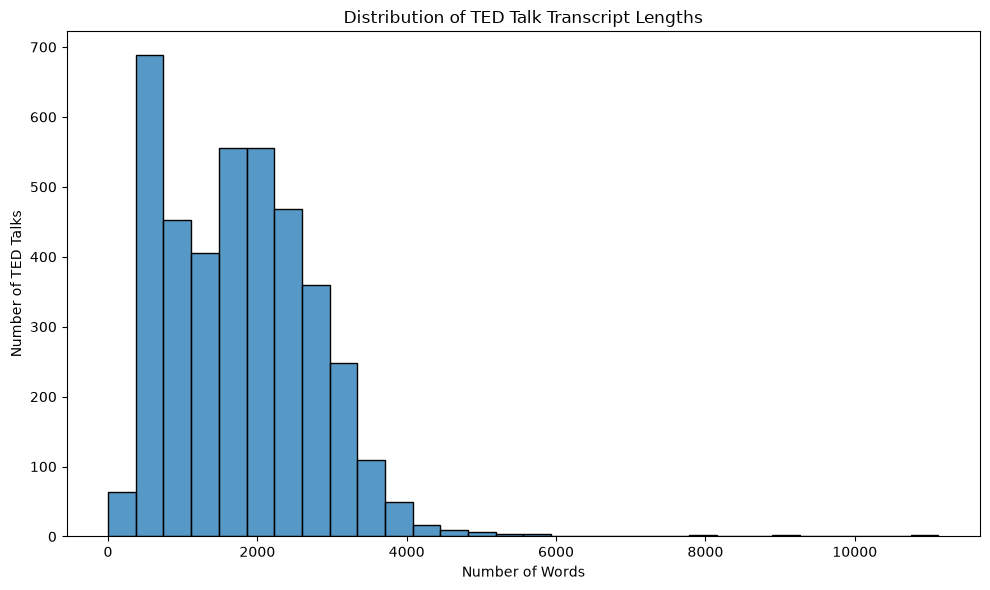

In [9]:
if "transcript" in df.columns:
    transcript_words = (
        df["transcript"]
        .fillna("")
        .astype(str)
        .str.split()
        .str.len()
    )

    plt.figure(figsize=(10, 6))
    sns.histplot(transcript_words, bins=30)

    plt.xlabel("Number of Words")
    plt.ylabel("Number of TED Talks")
    plt.title("Distribution of TED Talk Transcript Lengths")
    plt.tight_layout()
    plt.show()
else:
    print("Transcript column is not available.")

In [10]:
if "topics" in df.columns:
    print("Sample TED Talk topics:")
    print(df["topics"].head(10).to_string(index=False))

    print("\nExample data type:")
    print(type(df["topics"].dropna().iloc[0]))
else:
    print("The topics column is not available.")

Sample TED Talk topics:
['alternative energy', 'cars', 'climate change'...
['Africa', 'Asia', 'Google', 'demo', 'economics...
['computers', 'entertainment', 'interface desig...
['MacArthur grant', 'activism', 'business', 'ci...
['children', 'creativity', 'culture', 'dance', ...
['architecture', 'collaboration', 'culture', 'd...
['Christianity', 'God', 'atheism', 'comedy', 'c...
['God', 'atheism', 'brain', 'cognitive science'...
['Christianity', 'God', 'culture', 'happiness',...
['TED Prize', 'culture', 'entertainment', 'film...

Example data type:
<class 'str'>


In [11]:
if "topics" in df.columns:
    all_topics = (
        df["topics"]
        .dropna()
        .astype(str)
        .str.split(",")
        .explode()
        .str.strip()
    )

    all_topics = all_topics[all_topics != ""]

    topic_counts = all_topics.value_counts()

    print("Top 15 TED Talk topics:")
    display(topic_counts.head(15))
else:
    print("Topics column is not available.")

Top 15 TED Talk topics:


topics
'science'          816
'technology'       619
'culture'          522
'global issues'    511
'society'          462
'social change'    439
'design'           429
'health'           357
'humanity'         354
'history'          337
'innovation'       333
'technology']      329
['TEDx'            327
'animation'        327
'education'        326
Name: count, dtype: int64

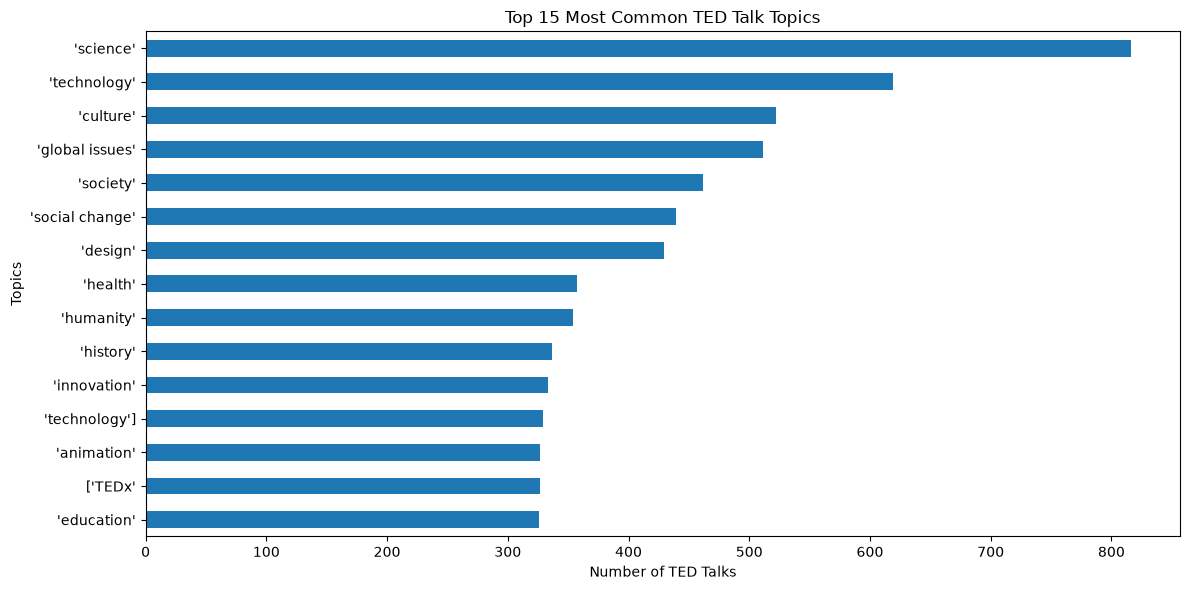

In [12]:
if "topics" in df.columns:
    plt.figure(figsize=(12, 6))

    topic_counts.head(15).sort_values().plot(
        kind="barh"
    )

    plt.xlabel("Number of TED Talks")
    plt.ylabel("Topics")
    plt.title("Top 15 Most Common TED Talk Topics")

    plt.tight_layout()
    plt.show()
else:
    print("Topics column is not available.")

In [13]:
if "views" in df.columns:
    print("Views Statistics:")
    display(df["views"].describe())

    print("\nTalks with zero or negative views:")
    print((df["views"] <= 0).sum())
else:
    print("Views column is not available.")

Views Statistics:


count    4.005000e+03
mean     2.148006e+06
std      3.451226e+06
min      0.000000e+00
25%      8.820690e+05
50%      1.375508e+06
75%      2.133110e+06
max      6.505195e+07
Name: views, dtype: float64


Talks with zero or negative views:
6


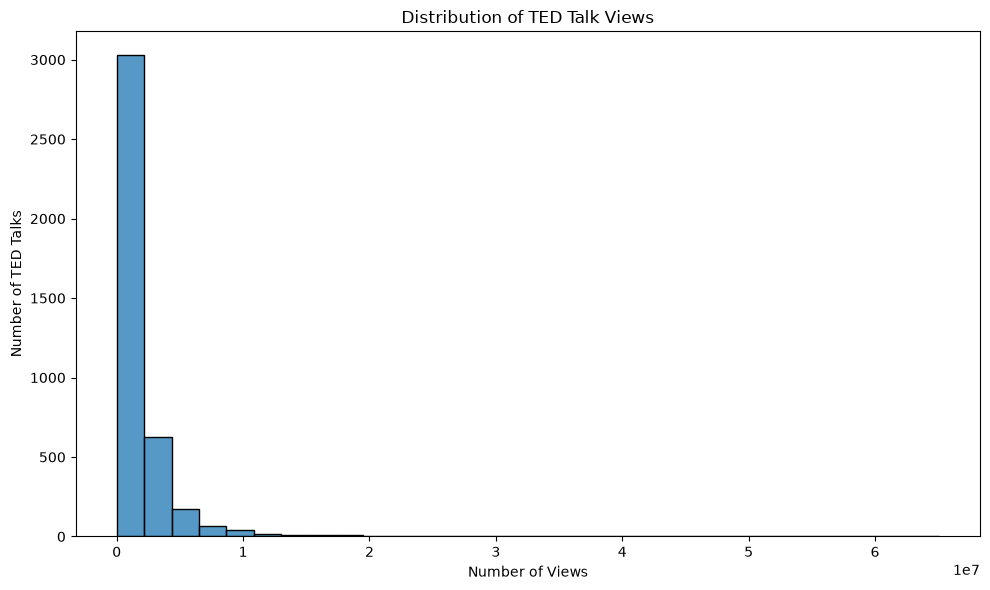

In [14]:
if "views" in df.columns:
    plt.figure(figsize=(10, 6))

    sns.histplot(df["views"].dropna(), bins=30)

    plt.xlabel("Number of Views")
    plt.ylabel("Number of TED Talks")
    plt.title("Distribution of TED Talk Views")

    plt.tight_layout()
    plt.show()
else:
    print("Views column is not available.")

In [15]:
if "duration" in df.columns:
    print("TED Talk Duration Statistics:")
    display(df["duration"].describe())

    print("\nTalks with zero or negative duration:")
    print((df["duration"] <= 0).sum())
else:
    print("Duration column is not available.")

TED Talk Duration Statistics:


count    4005.000000
mean      724.011236
std       361.775462
min        60.000000
25%       393.000000
50%       738.000000
75%       974.000000
max      3922.000000
Name: duration, dtype: float64


Talks with zero or negative duration:
0


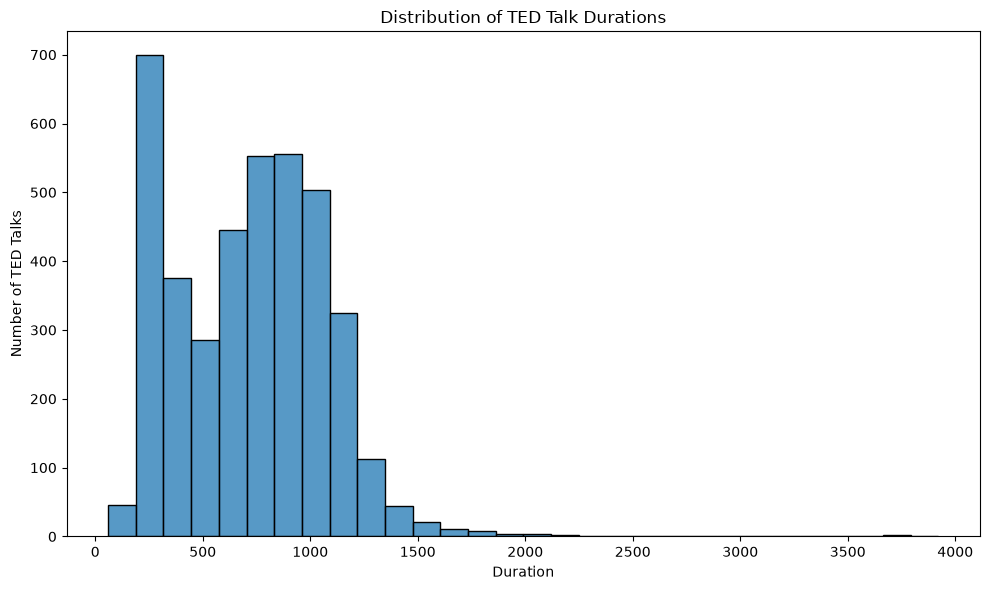

In [16]:
if "duration" in df.columns:
    plt.figure(figsize=(10, 6))

    sns.histplot(df["duration"].dropna(), bins=30)

    plt.xlabel("Duration")
    plt.ylabel("Number of TED Talks")
    plt.title("Distribution of TED Talk Durations")

    plt.tight_layout()
    plt.show()
else:
    print("Duration column is not available.")

In [17]:
print("Data Quality Checks")

if "views" in df.columns:
    print("Negative views:", (df["views"] < 0).sum())

if "duration" in df.columns:
    print("Negative durations:", (df["duration"] < 0).sum())

if "title" in df.columns:
    print("Missing titles:", df["title"].isnull().sum())
    print(
        "Empty titles:",
        df["title"].fillna("").astype(str).str.strip().eq("").sum()
    )

if "url" in df.columns:
    print("Missing URLs:", df["url"].isnull().sum())
    print(
        "Empty URLs:",
        df["url"].fillna("").astype(str).str.strip().eq("").sum()
    )

Data Quality Checks
Negative views: 0
Negative durations: 0
Missing titles: 0
Empty titles: 0
Missing URLs: 0
Empty URLs: 0



## Exploratory Data Analysis Findings

### 1. Dataset Overview
The TED Talks dataset contains 4005 rows and 19 columns.

### 2. Missing Values
Some columns contain missing values. These should be investigated before data cleaning.

### 3. Duplicate Records
The dataset should be checked for duplicate rows and repeated talk IDs before preprocessing.

### 4. Transcript Length
Transcript word counts help identify empty or unusually short transcripts.

### 5. Topic Distribution
The top 15 topics show which subjects appear most frequently in the TED Talks dataset.

### 6. Views and Duration
Views and duration statistics and charts help identify distributions and potentially unusual values.



## Proposed Data Cleaning Plan

1. **Missing Values:** Investigate missing values in each column and decide whether to fill them, retain them, or exclude affected records based on their importance.

2. **Duplicate Records:** Check duplicate rows and repeated talk IDs. Investigate duplicates before deciding whether any records should be removed.

3. **Text Cleaning:** Handle missing or empty titles, descriptions, topics, and transcripts appropriately.

4. **Text Preprocessing:** Remove unnecessary whitespace and prepare transcript and description text for analysis and recommendation.

5. **Topic Standardization:** Standardize topic formatting and investigate inconsistent topic labels.

6. **Views and Duration:** Check invalid or unusual values and investigate them before deciding how to handle them.

7. **Preserve Original Data:** Keep the original dataset unchanged. Perform cleaning on a separate working copy and document all changes.
